# 05｜進階 RNN 架構：Stacked、Hybrid、Bidirectional

| Run | 架構（Embedding 後） | 對照 |
|---|---|---|
| DL-07 | LSTM(64, return_sequences=True) → LSTM(64) | DL-02 |
| DL-08 | LSTM(64, return_sequences=True) → GRU(64) | DL-02／DL-03 |
| DL-09 | Bidirectional(LSTM(64)) | DL-02 |
| DL-10 | Bidirectional(GRU(64)) | DL-03 |

不加入 Dropout 或 EarlyStopping，保留共同 10 Epoch、Adam(0.001)、batch=128、同一 v1.1 Token IDs。這是架構比較而非等參數量比較；記錄實際參數量與耗時。


In [1]:
from pathlib import Path
import json,sys
ROOT=Path('/workspace/imdb_matrix_experiment/variants/dedup_v1_1')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import yaml,numpy as np,pandas as pd
from IPython.display import display,Image
from src.common import file_hash
from src.evaluation import phase1_settings
base,base_sha,manifest=phase1_settings()
p=ROOT/'config/phase2_conditions.yaml'
cfg=yaml.safe_load(p.read_text(encoding='utf8'))
assert cfg['phase1_config_sha256']==base_sha
assert cfg['split_assignments_sha256']==manifest['split_assignments_sha256']
assert cfg['test_policy']=='do_not_evaluate_until_gate_e'
print('Variant:',manifest['version'],'Gate A SHA:',manifest['split_assignments_sha256'])
print('Phase 2 SHA:',file_hash(p))
print('Test policy:',cfg['test_policy'])
from src.evaluation import subset_data
train,val=subset_data()
assert len(train)==19823 and len(val)==4956
assert cfg['shared']['epochs']==10
print('Architectures:',cfg['architectures'])


Variant: dedup_v1.1 Gate A SHA: 9e25b0d714d1fb555c8c8a58fa6858c392ec60ecfba554b923553626154174e9
Phase 2 SHA: a13de8d435a85d888ae9565ed462c35630c88b61f0a6a7692e187e967ae436b4
Test policy: do_not_evaluate_until_gate_e
Architectures: {'DL-07': 'StackedLSTM', 'DL-08': 'LSTM_GRU', 'DL-09': 'BidirectionalLSTM', 'DL-10': 'BidirectionalGRU'}


## 1. 設計關鍵：輸出序列與雙向連結
兩層 LSTM / LSTM+GRU 的第一層必須 return_sequences=True，否則下一層收不到完整時間序列。雙向網路將正向和逆向狀態組合。

In [2]:
import tensorflow as tf
from src.phase2_factory import build_phase2
assert tf.config.list_physical_devices('GPU')
for rid in ('DL-07','DL-08','DL-09','DL-10'):
    tf.keras.utils.set_random_seed(42)
    m=build_phase2(rid,cfg['shared'])
    print(rid,cfg['architectures'][rid],m.count_params(),
          [(layer.name,layer.__class__.__name__) for layer in m.layers])
    if rid in ('DL-07','DL-08'):
        assert m.get_layer('lstm_1').return_sequences
    del m
    tf.keras.backend.clear_session()


I0000 00:00:1793793661.270206   23605 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4599 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060, pci bus id: 0000:02:00.0, compute capability: 7.5


DL-07 StackedLSTM 1275329 [('token_ids', 'InputLayer'), ('embedding', 'Embedding'), ('lstm_1', 'LSTM'), ('lstm_2', 'LSTM'), ('positive_probability', 'Dense')]
DL-08 LSTM_GRU 1267265 [('token_ids', 'InputLayer'), ('embedding', 'Embedding'), ('lstm_1', 'LSTM'), ('gru_2', 'GRU'), ('positive_probability', 'Dense')]
DL-09 BidirectionalLSTM 1284609 [('token_ids', 'InputLayer'), ('embedding', 'Embedding'), ('bidirectional_lstm', 'Bidirectional'), ('positive_probability', 'Dense')]


DL-10 BidirectionalGRU 1263873 [('token_ids', 'InputLayer'), ('embedding', 'Embedding'), ('bidirectional_gru', 'Bidirectional'), ('positive_probability', 'Dense')]


## 2. 執行四個進階架構
模型全部訓練 10 epochs，固定相同驗證程序，保存模型、loss history、Validation 預測與混淆矩陣。

In [3]:
import subprocess
wanted=[f'DL-{i:02d}-s42' for i in range(7,11)]
rows=pd.read_csv(ROOT/'results/runs.csv')
missing=[rid[:-4] for rid in wanted if rid not in set(rows.run_id)]
print('Missing advanced runs:',missing)
if missing:
    subprocess.run([sys.executable,'-B','-m','src.phase2_train','--runs',*missing],cwd=ROOT,check=True)
print('Four advanced architectures completed.')


Missing advanced runs: []
Four advanced architectures completed.


## 3. Validation 效能、參數量與成本
對比單層 LSTM、GRU 基準（DL-02、DL-03），不要把不同參數量的模型誤認為完全等成本比較。

In [4]:
baseline=['DL-02-s42','DL-03-s42']
ids=baseline+wanted
records=pd.read_csv(ROOT/'results/runs.csv')
selected=records[records.run_id.isin(ids)].set_index('run_id').loc[ids].reset_index()
assert len(selected)==6
display(selected[['run_id','model_name','val_accuracy','val_precision','val_recall','val_f1',
                  'val_loss','epochs_completed','trainable_params','train_time_sec',
                  'inference_time_sec']].round(4))


,run_id,model_name,val_accuracy,val_precision,val_recall,val_f1,val_loss,epochs_completed,trainable_params,train_time_sec,inference_time_sec
0,DL-02-s42,LSTM,0.8247,0.8525,0.7871,0.8185,0.7924,10.0,1242305.0,13.6681,0.1738
1,DL-03-s42,GRU,0.8099,0.8125,0.8080,0.8102,0.7745,10.0,1231937.0,12.2460,0.1640
2,DL-07-s42,StackedLSTM,0.7782,0.8461,0.6826,0.7556,0.8176,10.0,1275329.0,32.6990,0.3152
3,DL-08-s42,LSTM_GRU,0.8067,0.7945,0.8297,0.8117,0.9441,10.0,1267265.0,33.5900,0.3040
4,DL-09-s42,BidirectionalLSTM,0.8004,0.8186,0.7742,0.7958,0.5446,10.0,1284609.0,34.4293,0.3392
5,DL-10-s42,BidirectionalGRU,0.8216,0.8399,0.7967,0.8177,0.9158,10.0,1263873.0,32.6914,0.3146


## 4. 架構比較圖、訓練趨勢與混淆矩陣
以下圖表只包含 Validation，不使用 Test。

DL-07-s42


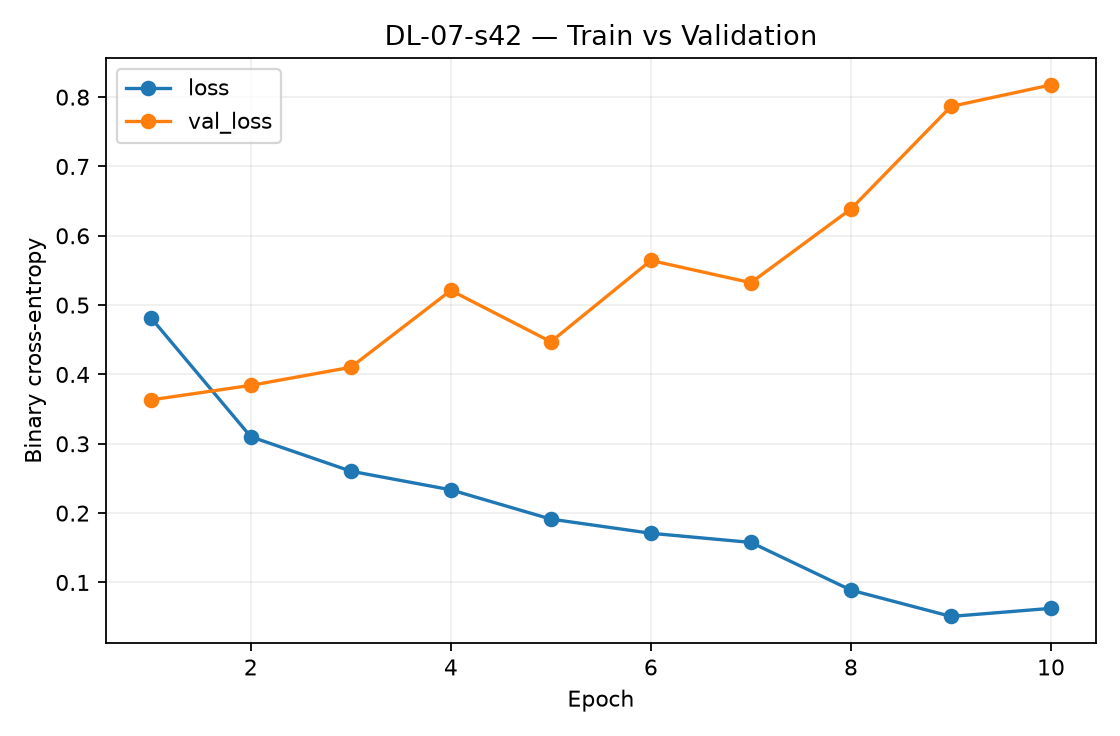

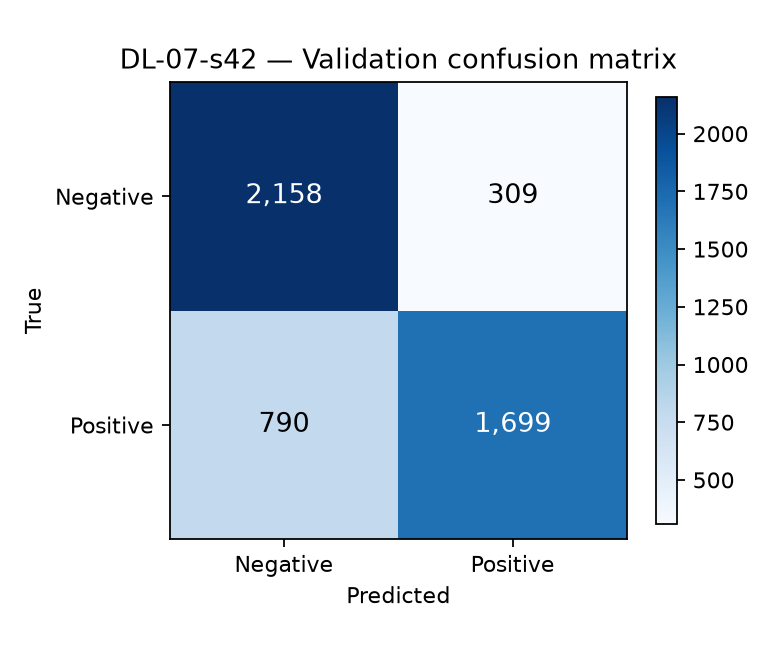

DL-08-s42


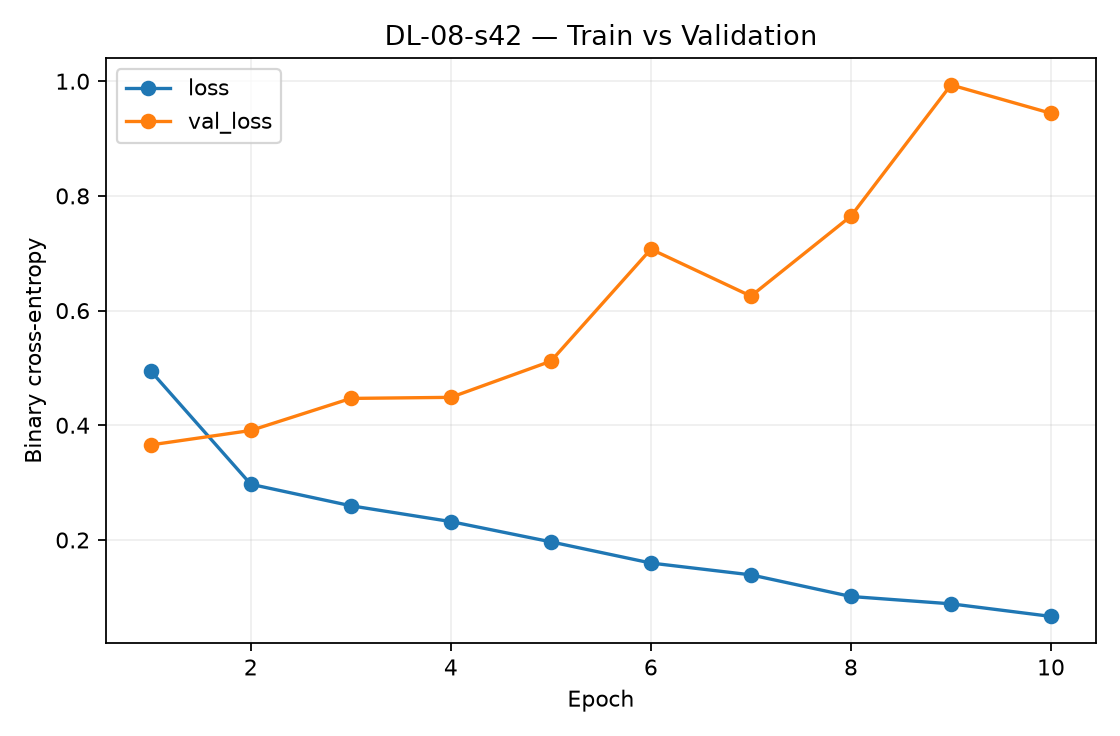

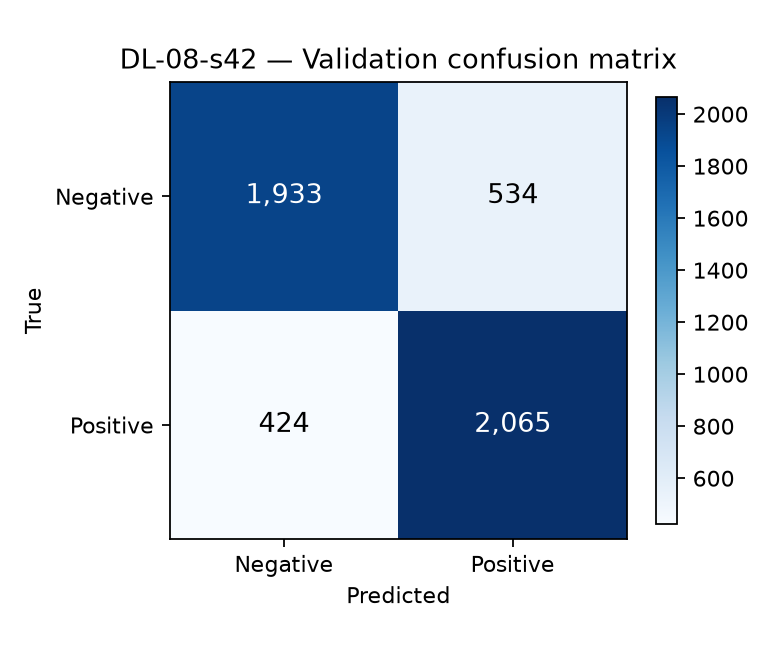

DL-09-s42


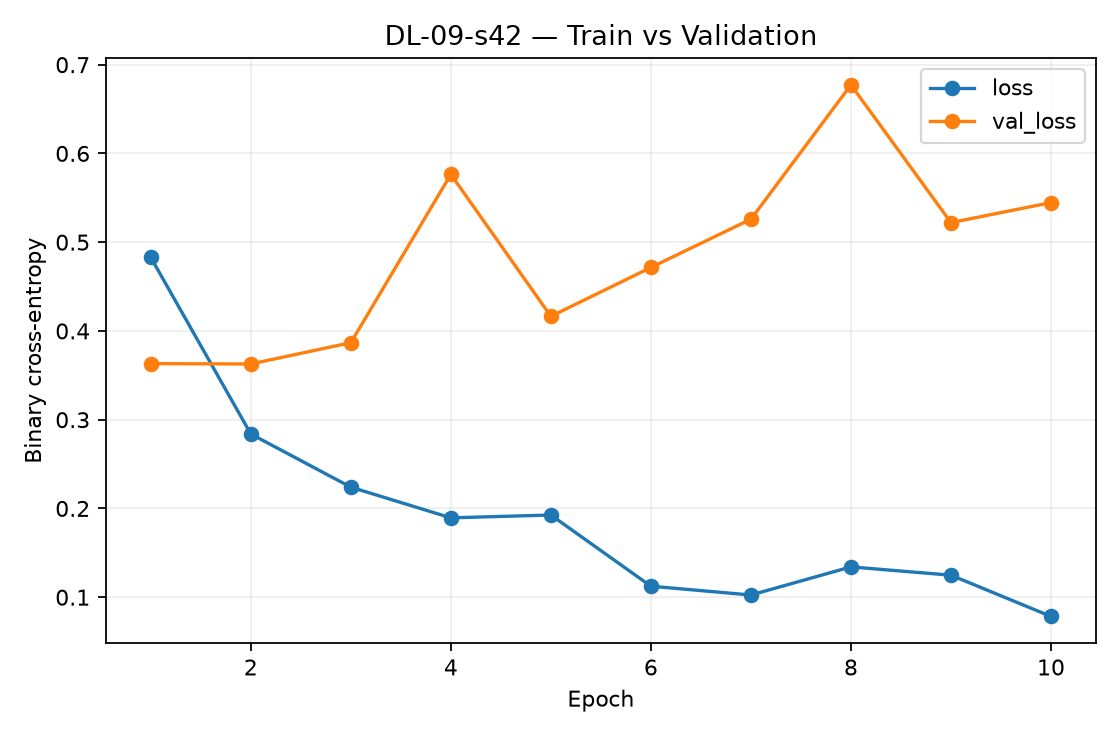

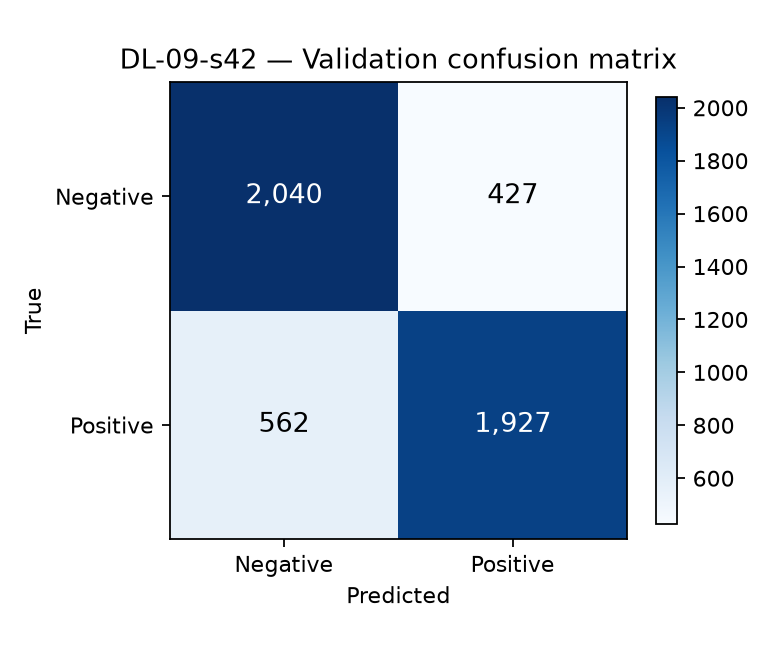

DL-10-s42


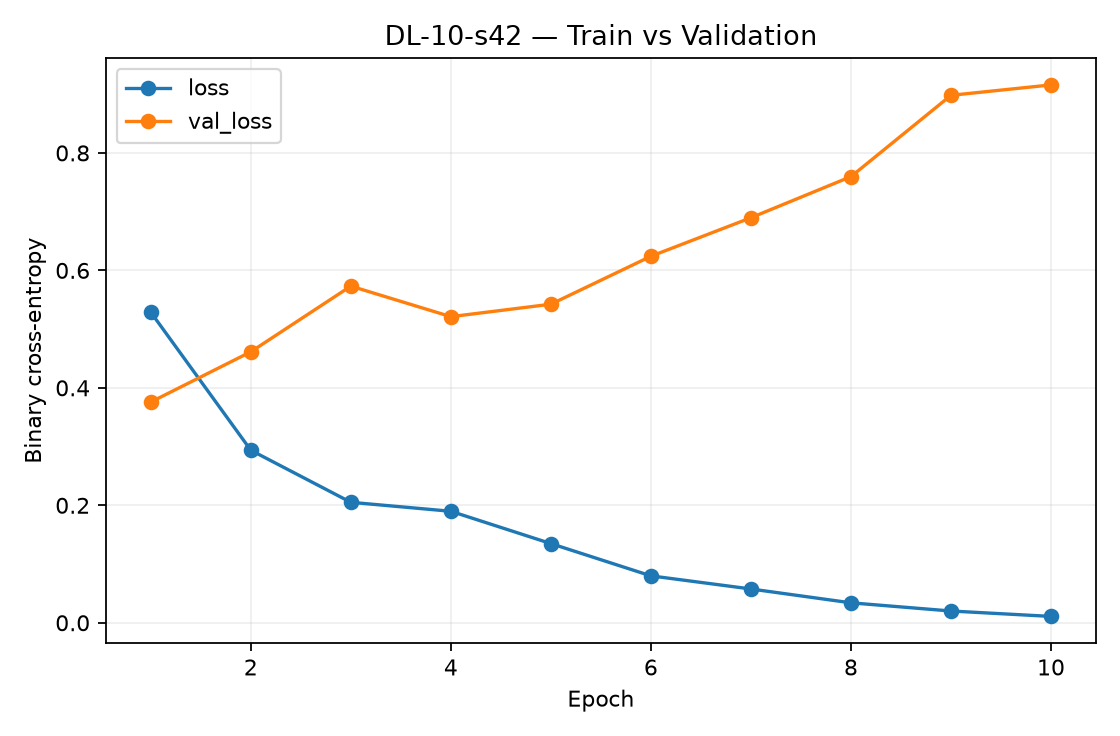

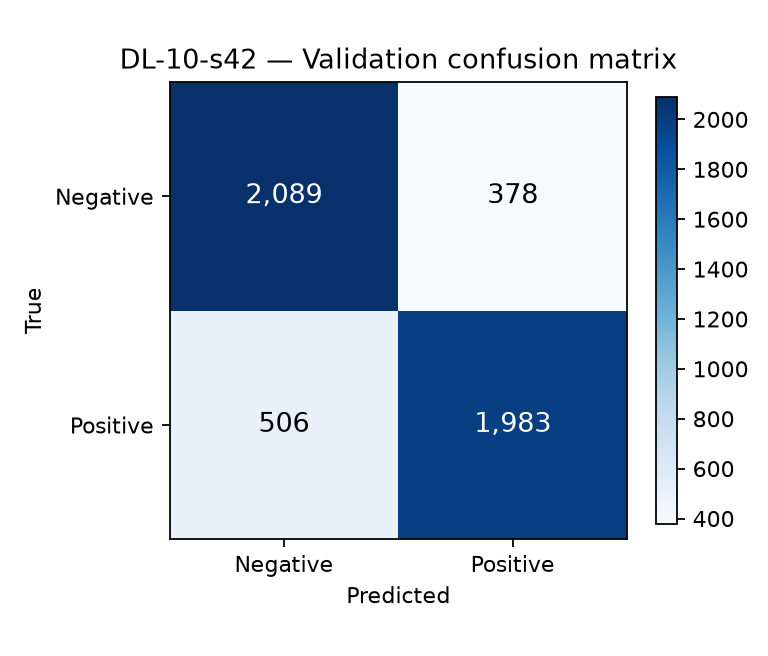

In [5]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,3.4))
ax.bar(selected.run_id,selected.val_f1)
ax.set(ylim=(0,1),ylabel='Validation F1',title='Advanced RNN vs single-layer baselines')
ax.grid(axis='y',alpha=.2)
plt.show()
for rid in wanted:
    print(rid)
    display(Image(filename=str(ROOT/f'results/figures/{rid}_learning_curve.png'),width=490))
    display(Image(filename=str(ROOT/f'results/figures/{rid}_val_confusion_matrix.png'),width=330))


## 小結
DL-07～DL-10 以共同輸入、相同 Epoch 預算進行架構比較；總參數量及訓練秒數各有差異。正式最終 Test 評估需等所有架構以 Validation 選定後才執行。